# Project 3: Reusable Data Quality Report (Palmer Penguins)
A small reusable function that audits any CSV (missing values, duplicates, outliers, odd categories) and prints a short report. Demo on the public Palmer Penguins dataset.

In [1]:
import pandas as pd, numpy as np
def quality_report(df, z=3.0):
    out={}
    out["shape"]=df.shape
    out["duplicate_rows"]=int(df.duplicated().sum())
    out["missing"]=df.isna().sum()[lambda s:s>0].to_dict()
    num=df.select_dtypes("number")
    out["outliers_zscore"]={c:int((((num[c]-num[c].mean())/num[c].std()).abs()>z).sum()) for c in num}
    out["text_issues"]={c:int((df[c].dropna()!=df[c].dropna().str.strip().str.lower()).sum()) for c in df.select_dtypes("object")}
    out["categories"]={c:df[c].dropna().unique().tolist() for c in df.select_dtypes("object") if df[c].nunique()<=10}
    return out
df=pd.read_csv("penguins.csv")
r=quality_report(df)
for k,v in r.items(): print(k,":",v)

shape : (344, 7)
duplicate_rows : 0
missing : {'bill_length_mm': 2, 'bill_depth_mm': 2, 'flipper_length_mm': 2, 'body_mass_g': 2, 'sex': 11}
outliers_zscore : {'bill_length_mm': 0, 'bill_depth_mm': 0, 'flipper_length_mm': 0, 'body_mass_g': 0}
text_issues : {'species': 344, 'island': 344, 'sex': 333}
categories : {'species': ['Adelie', 'Chinstrap', 'Gentoo'], 'island': ['Torgersen', 'Biscoe', 'Dream'], 'sex': ['MALE', 'FEMALE']}


## Findings and fixes
- Missing values appear in the measurements and in `sex`.
- Rows with no measurements at all carry no information, so drop them.
- Remaining missing sex values are kept as "unknown" for analysis.

In [2]:
clean=df.dropna(subset=["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]).copy()
clean["sex"]=clean["sex"].fillna("unknown").str.lower()
print(df.shape,"->",clean.shape); quality_report(clean)["missing"]

(344, 7) -> (342, 7)


{}

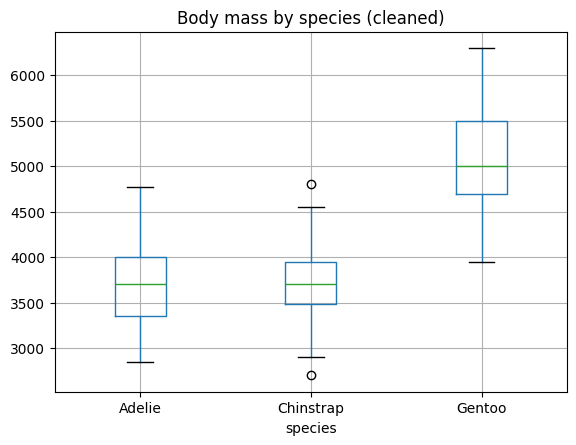

In [3]:
import matplotlib.pyplot as plt
clean.boxplot(column="body_mass_g",by="species"); plt.suptitle(""); plt.title("Body mass by species (cleaned)"); plt.show()

## How a client benefits
Send any messy CSV and get: this audit, a cleaned file, and a list of every change made so nothing is hidden.